# Phase 1B: Yield label statistics and outliers

**Input:** `data/processed_v2/yield_analysis_ready_v2.gpkg` (1,205 fields, from R5)
**Output:** `data/processed_v2/yield_labels_v2.gpkg` (same fields plus outlier columns), tables in `results/phase1b/`, figures in `reports/figures/phase1b/`

The yield is the thing the model will predict, so we must trust it. This notebook asks:
1. What unit is the yield in?
2. Which yields are impossible?
3. What does the yield look like (centre, spread, shape)?
4. Did people round their yields?
5. Which yields are unusual, by several methods?
6. Which fields do several methods agree on?
7. Do the R4 doubt flags go with lower or higher yields?

We **flag** fields here. We do not delete them. Phase 6 tests what to do with them.

Spatial outliers (LISA) wait for Phase 2. The multivariate check waits for the SAR features.

## Step 1: What unit is the yield in?

The column `crop_yield` has no unit. Farmers in Maharashtra say "quintal per acre" (q/acre), but reports use "quintal per hectare" (q/ha). 1 q/acre = 247.1 kg/ha and 1 q/ha = 100 kg/ha, so the choice changes every value by 2.5 times.

We compare the median yield in each year with:
- **(a) the official soybean yield of Latur district** (VNMKV regional extension centre, Latur, RRC 2025 report)
- **(b) the simulated potential yield** of soybean in India (Bhatia et al. 2008, CROPGRO model, 21 locations): 2,170 kg/ha with rain only, 3,020 kg/ha with no water limit

The unit that sits closer (on a log scale) wins for that year.

In [1]:
from pathlib import Path
import numpy as np
import pandas as pd
import geopandas as gpd
from scipy import stats
import matplotlib.pyplot as plt

here = Path.cwd()
ROOT = here if (here / "data" / "raw").exists() else here.parent
DATA2 = ROOT / "data" / "processed_v2"
OUT = ROOT / "results" / "phase1b"; OUT.mkdir(parents=True, exist_ok=True)
FIG = ROOT / "reports" / "figures" / "phase1b"; FIG.mkdir(parents=True, exist_ok=True)
plt.rcParams.update({"font.family": "Times New Roman", "font.size": 12,
                     "axes.spines.top": False, "axes.spines.right": False})

f = gpd.read_file(DATA2 / "yield_analysis_ready_v2.gpkg")
print("fields:", len(f))

Q_ACRE_TO_KG_HA = 100 * 2.4710538      # 1 q/acre = 247.1 kg/ha
# (a) official soybean productivity of Latur district, kg/ha (VNMKV regional extension centre, Latur, RRC 2025)
OFFICIAL = {2022: 1100, 2023: 1551, 2024: 1998}
# (b) simulated potential yield of rainfed soybean in India, kg/ha (Bhatia et al. 2008, CROPGRO-Soybean, 21 locations)
POT_WATER_LIMITED, POT_NO_WATER_LIMIT = 2170, 3020

y = f["crop_yield"].where(f["crop_yield"].between(0.01, 60))   # 0, 260 and 720 left out here (Step 2)
rows = []
for yr in sorted(f["year"].unique()):
    med = y[f["year"] == yr].median()
    as_acre, as_ha = med * Q_ACRE_TO_KG_HA, med * 100
    off = OFFICIAL.get(yr)
    rows.append({"year": yr, "fields": int(y[f["year"] == yr].notna().sum()), "median_recorded": med,
                 "if_q_per_acre_kg_ha": round(as_acre), "if_q_per_ha_kg_ha": round(as_ha), "official_kg_ha": off,
                 "closer_to_official": None if off is None else
                     ("q/acre" if abs(np.log(as_acre / off)) < abs(np.log(as_ha / off)) else "q/ha")})
units = pd.DataFrame(rows)
units.to_csv(OUT / "B1_unit_check.csv", index=False)
print(units.to_string(index=False))
med_all = y.median()
print(f"\nall years, median {med_all}: as q/acre {med_all * Q_ACRE_TO_KG_HA:,.0f} kg/ha, as q/ha {med_all * 100:,.0f} kg/ha")
print(f"simulated potential: {POT_WATER_LIMITED:,} kg/ha (water-limited), {POT_NO_WATER_LIMIT:,} kg/ha (no water limit)")
print(f"  as q/acre the median is {100 * med_all * Q_ACRE_TO_KG_HA / POT_WATER_LIMITED:.0f}% of the water-limited potential; "
      f"as q/ha it is {100 * med_all * 100 / POT_WATER_LIMITED:.0f}%")

UNIT = "q/acre"                                  # decision, see the Found line
f["yield_kg_ha"] = f["crop_yield"] * Q_ACRE_TO_KG_HA

fields: 1205
 year  fields  median_recorded  if_q_per_acre_kg_ha  if_q_per_ha_kg_ha  official_kg_ha closer_to_official
 2022      55              9.0                 2224                900          1100.0               q/ha
 2023      58              8.0                 1977                800          1551.0             q/acre
 2024     323              9.5                 2348                950          1998.0             q/acre
 2025     766              8.0                 1977                800             NaN                NaN

all years, median 8.2: as q/acre 2,026 kg/ha, as q/ha 820 kg/ha
simulated potential: 2,170 kg/ha (water-limited), 3,020 kg/ha (no water limit)
  as q/acre the median is 93% of the water-limited potential; as q/ha it is 38%


**Found:**
- 2023 and 2024 are closer as q/acre (1,977 and 2,348 kg/ha vs official 1,551 and 1,998). 2022 is closer as q/ha (900 vs 1,100).
- As q/ha the median would be 820 kg/ha, only 38% of the rainfed potential and below every official year. As q/acre it is 2,026 kg/ha, 93% of the rainfed potential.
- Survey areas are recorded in acres (R3), so the survey team worked in acres.
- **Decision: q/acre.** Two of three years, the area unit, and the potential yield all point this way.
- **Limit:** 2022 does not fit, and the sample fields are probably better farmed than the district average, so the evidence is not certain. The outlier methods in Step 5 do not depend on the unit (they compare yields with each other). Only the agronomic check does. A new column `yield_kg_ha` stores the converted value.

## Step 2: Impossible yields

A yield of 0 means no crop, so the field cannot be a label for a soybean yield model. A yield above the world record is not physically possible.

**World record:** 206.8 bushels per acre (Alex Harrell, Georgia, USA, 2023). One bushel of soybean = 60 lb, so 1 bu/acre = 67.25 kg/ha.

In [2]:
# hard physical bounds: no crop yield can be 0 or below, or above the world record
# world record soybean yield: 206.8 bu/acre (Alex Harrell, Georgia, 2023) = 206.8 * 67.25 kg/ha = 13,907 kg/ha
WORLD_RECORD_KG_HA = 206.8 * 67.25
LIMIT_Q_ACRE = WORLD_RECORD_KG_HA / Q_ACRE_TO_KG_HA
f["flag_yield_impossible"] = (f["crop_yield"] <= 0) | (f["crop_yield"] > LIMIT_Q_ACRE)
print(f"world record = {WORLD_RECORD_KG_HA:,.0f} kg/ha = {LIMIT_Q_ACRE:.1f} q/acre")
print("impossible yields:", int(f["flag_yield_impossible"].sum()),
      "| values:", sorted(f.loc[f["flag_yield_impossible"], "crop_yield"].tolist()),
      "| years:", f.loc[f["flag_yield_impossible"], "year"].tolist())
ok = ~f["flag_yield_impossible"]
print("fields with a possible yield:", int(ok.sum()))

world record = 13,907 kg/ha = 56.3 q/acre
impossible yields: 3 | values: [0.0, 260.0, 720.0] | years: [2023, 2023, 2025]
fields with a possible yield: 1202


**Found:**
- The world record is 13,907 kg/ha = 56.3 q/acre (or 139 q/ha, so the result is the same in either unit).
- 3 yields are impossible: **0** (2023), **260** (2023) and **720** (2025). These are the same 3 fields that were only in v2 (R5 Step 5).
- These 3 are left out of Steps 3 to 7, which use the other 1,202 fields.

## Step 3: Descriptive statistics

Overall and per year, variety, taluka and irrigation. Then a Kruskal-Wallis test: does the yield differ between years? If yes, outliers should also be judged inside each year (Step 5, per-group method).

In [3]:
def describe(v):
    v = v.dropna()
    q = v.quantile([0.01, 0.05, 0.25, 0.5, 0.75, 0.95, 0.99])
    return pd.Series({"n": len(v), "mean": v.mean(), "median": q[0.5], "sd": v.std(), "cv_%": 100 * v.std() / v.mean(),
                      "min": v.min(), "p1": q[0.01], "p5": q[0.05], "q1": q[0.25], "q3": q[0.75], "p95": q[0.95],
                      "p99": q[0.99], "max": v.max(), "iqr": q[0.75] - q[0.25], "skew": v.skew(), "kurtosis": v.kurt()})

d = f[ok]
tabs = [describe(d["crop_yield"]).to_frame("all").T.assign(group="all")]
for col in ["year", "variety", "taluka", "irrigation"]:
    t = d.groupby(col)["crop_yield"].apply(describe).unstack()
    t.index = [f"{col}: {i}" for i in t.index]; tabs.append(t.assign(group=col))
label_stats = pd.concat(tabs).round(2)
label_stats.to_csv(OUT / "B3_label_stats.csv")
print("yield (q/acre), fields with a possible yield")
print(label_stats[["n", "mean", "median", "sd", "cv_%", "min", "q1", "q3", "max", "skew", "kurtosis"]].to_string())

# does yield differ between years? (Kruskal-Wallis) - this decides whether outliers are judged per year
kw = stats.kruskal(*[g["crop_yield"] for _, g in d.groupby("year")])
print(f"\nyield differs between years: Kruskal-Wallis H = {kw.statistic:.1f}, p = {kw.pvalue:.1e}")

yield (q/acre), fields with a possible yield
                                  n   mean  median    sd   cv_%   min    q1     q3   max  skew  kurtosis
all                          1202.0   8.62    8.20  3.09  35.88  1.00  7.00  10.00  47.0  3.53     33.09
year: 2022                     55.0   8.33    9.00  2.93  35.19  2.00  6.25  10.00  15.0 -0.13     -0.49
year: 2023                     58.0   8.63    8.00  2.64  30.54  3.00  7.00   9.88  20.0  1.50      5.22
year: 2024                    323.0  10.10    9.50  4.05  40.12  3.50  8.00  11.50  47.0  4.76     33.19
year: 2025                    766.0   8.02    8.00  2.39  29.79  1.00  6.66   9.10  24.0  0.67      4.16
variety: AMS 1001              12.0   7.98    7.50  2.47  31.01  5.00  6.38   9.12  14.0  1.29      2.17
variety: DS 228               293.0   7.93    8.00  2.98  37.55  1.00  6.50   9.00  38.0  5.22     48.97
variety: JS 335                99.0   8.21    8.00  2.86  34.82  2.00  7.00   9.00  24.0  2.49     12.15
variety: K

**Found:**
- All years: median **8.2 q/acre**, mean 8.62, SD 3.09, range 1 to 47.
- 2024 is higher than the other years (median 9.5, mean 10.10) and has the widest spread (SD 4.05). 2022, 2023 and 2025 have medians of 8 to 9.
- The yield differs between years (H = 110.9, p < 0.001), so per-year groups are needed in Step 5.
- KDS 726 has the highest median (10.25). Ausa taluka has the biggest spread (CV 53%), because the top yields (32 to 47) are there.
- Irrigated fields (Flow/Protective, Drip) have a median of 9, rainfed fields 8.
- Skewness 3.53 means a long tail on the high side.

## Step 4: Shape of the distribution

Histogram with a smooth curve (KDE), box plots per year, and a Q-Q plot. Two tests check if the yield follows a normal (bell) curve: Shapiro-Wilk and D'Agostino K². This matters because "mean ± 3 SD" and Grubbs assume a bell curve.

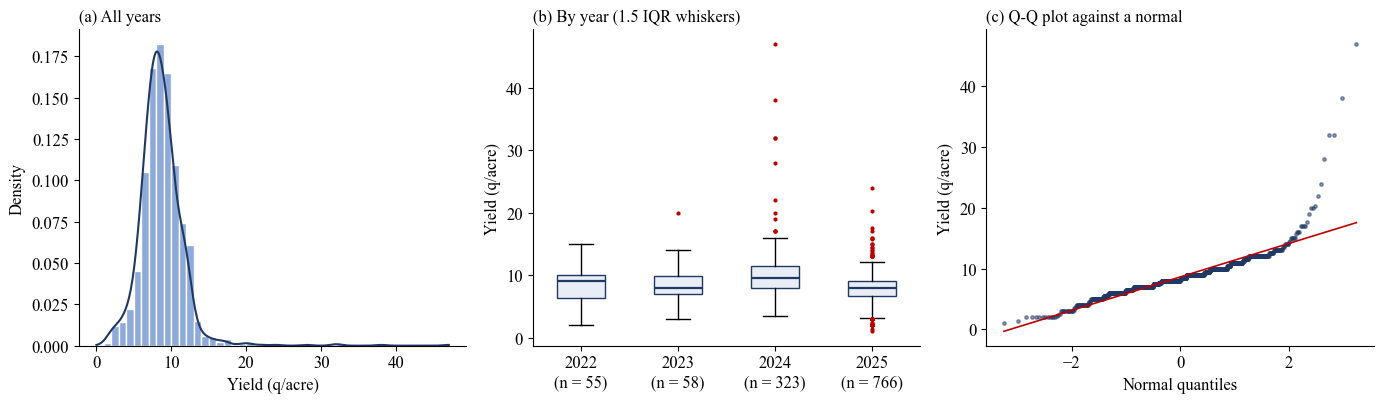

Shapiro-Wilk W = 0.792, p = 1.2e-36 | D'Agostino K2 = 1015.8, p = 2.7e-221
skewness 3.53, excess kurtosis 33.09


In [4]:
yv = d["crop_yield"]
fig, axes = plt.subplots(1, 3, figsize=(14, 4.2))
ax = axes[0]
ax.hist(yv, bins=np.arange(0, yv.max() + 1, 1), color="#8EA9DB", edgecolor="white", density=True)
xs = np.linspace(0, yv.max(), 400); ax.plot(xs, stats.gaussian_kde(yv)(xs), color="#1F3864", lw=1.5)
ax.set_xlabel("Yield (q/acre)"); ax.set_ylabel("Density"); ax.set_title("(a) All years", loc="left", fontsize=12)
ax = axes[1]
yrs = sorted(d["year"].unique())
ax.boxplot([d.loc[d["year"] == y_, "crop_yield"] for y_ in yrs], widths=0.5, patch_artist=True,
           boxprops=dict(facecolor="#E8EDF6", edgecolor="#1F3864"), medianprops=dict(color="#1F3864", lw=1.6),
           flierprops=dict(marker="o", markersize=3, markerfacecolor="#C00000", markeredgecolor="none"))
ax.set_xticks(range(1, len(yrs) + 1), [f"{y_}\n(n = {(d['year'] == y_).sum()})" for y_ in yrs])
ax.set_ylabel("Yield (q/acre)"); ax.set_title("(b) By year (1.5 IQR whiskers)", loc="left", fontsize=12)
ax = axes[2]
(osm, osr), (slope, inter, r) = stats.probplot(yv, dist="norm")
ax.scatter(osm, osr, s=6, color="#1F3864", alpha=0.5); ax.plot(osm, slope * osm + inter, color="#C00000", lw=1.2)
ax.set_xlabel("Normal quantiles"); ax.set_ylabel("Yield (q/acre)"); ax.set_title("(c) Q-Q plot against a normal", loc="left", fontsize=12)
fig.tight_layout(); fig.savefig(FIG / "B4_yield_distribution.png", dpi=300, facecolor="white"); plt.show()

sw = stats.shapiro(yv); da = stats.normaltest(yv)
print(f"Shapiro-Wilk W = {sw.statistic:.3f}, p = {sw.pvalue:.1e} | D'Agostino K2 = {da.statistic:.1f}, p = {da.pvalue:.1e}")
print(f"skewness {yv.skew():.2f}, excess kurtosis {yv.kurt():.2f}")

**Found:**
- The yield is **not** normal: Shapiro-Wilk W = 0.792, D'Agostino K² = 1,015.8, both p < 0.001.
- The Q-Q plot bends up at the right end: a few very high yields make the long tail.
- So methods that assume a bell curve (mean ± 3 SD, Grubbs, Rosner) are less reliable here. Robust methods (IQR, modified z-score) are better. We run both kinds and compare.

## Step 5: Rounding

If yields were measured exactly, the first decimal would be spread evenly over 0 to 9 (10% each). A chi-square test checks this. Many whole numbers (.0) or half steps (.5) mean the yield was estimated or rounded.

In [5]:
dec = (d["crop_yield"] * 10).round().astype(int) % 10          # first decimal digit, 0 to 9
rows = []
for name, m in [("all", pd.Series(True, index=d.index))] + [(f"year {y_}", d["year"] == y_) for y_ in yrs]:
    c = dec[m].value_counts().reindex(range(10), fill_value=0)
    chi = stats.chisquare(c)                                      # even spread over 0 to 9 if measured exactly
    rows.append({"group": name, "n": int(m.sum()), "whole_%": round(100 * c[0] / c.sum(), 1),
                 "half_step_%": round(100 * c[5] / c.sum(), 1), "other_%": round(100 * c[[1, 2, 3, 4, 6, 7, 8, 9]].sum() / c.sum(), 1),
                 "chi_square": round(chi.statistic, 1), "p": chi.pvalue})
for v_, g in d.groupby("variety"):
    if len(g) >= 30:
        c = dec[g.index].value_counts().reindex(range(10), fill_value=0)
        rows.append({"group": f"variety {v_}", "n": len(g), "whole_%": round(100 * c[0] / c.sum(), 1),
                     "half_step_%": round(100 * c[5] / c.sum(), 1), "other_%": round(100 * c[[1, 2, 3, 4, 6, 7, 8, 9]].sum() / c.sum(), 1),
                     "chi_square": round(stats.chisquare(c).statistic, 1), "p": stats.chisquare(c).pvalue})
rounding = pd.DataFrame(rows)
rounding.to_csv(OUT / "B5_rounding.csv", index=False)
pd.set_option("display.float_format", lambda x: f"{x:.3g}")
print(rounding.to_string(index=False))
print("\n10 most common values:", d["crop_yield"].value_counts().head(10).to_dict())

           group    n  whole_%  half_step_%  other_%  chi_square         p
             all 1202     70.5         16.8     12.6    5.15e+03         0
       year 2022   55     89.1         10.9        0         388  4.75e-78
       year 2023   58     79.3         15.5      5.2         321  7.81e-64
       year 2024  323     71.5         19.5        9    1.46e+03 3.79e-308
       year 2025  766     68.1         16.2     15.7    3.02e+03         0
  variety DS 228  293     68.9         20.5     10.6    1.23e+03 5.39e-259
  variety JS 335   99     72.7         14.1     13.1         447  1.05e-90
 variety KDS 726   48     66.7         20.8     12.5         188  9.56e-36
 variety KDS 753  469     72.9         14.7     12.4    2.14e+03         0
 variety KDS 992  105     66.7         13.3       20         388  6.43e-78
variety MAUS 612   94     61.7         22.3       16         317  7.68e-63
 variety Unknown   45     95.6          4.4        0         367  1.66e-73

10 most common values: {

**Found:**
- **70.5%** of yields are whole numbers and 16.8% end in .5. Only 12.6% have another decimal (we would expect 80% if measured exactly).
- Rounding is strong in every year and variety (all p < 0.001). It drops over time: 89% whole in 2022, 68% in 2025.
- The 10 most common values are all whole or half numbers: 8, 9, 7, 10 lead.
- **Meaning:** the yield is accurate to about ±0.5 q/acre at best. A model error below that cannot be checked. Rounding also makes many ties, which the robust methods handle fine.

## Step 6: Outlier methods

Eight methods, each answering "is this yield unusual?":

| Method | Rule | Assumes bell curve? |
|---|---|---|
| Mean ± 3 SD | more than 3 SD from the mean | yes |
| IQR 1.5 | outside Q1 − 1.5 IQR to Q3 + 1.5 IQR (Tukey 1977) | no |
| IQR 3 | outside Q1 − 3 IQR to Q3 + 3 IQR ("far out") | no |
| Modified z-score | \|M\| > 3.5, M = 0.6745 (x − median) / MAD (Iglewicz and Hoaglin 1993) | no |
| Grubbs | the single most extreme value, α = 0.05 (Grubbs 1969) | yes |
| Rosner (generalized ESD) | up to 20 outliers, α = 0.05 (Rosner 1983) | yes |
| Per group | modified z-score inside each year × variety group with 30 or more fields | no |
| Above potential | above 3,020 kg/ha = 12.2 q/acre (Bhatia et al. 2008) | no |

In [6]:
def generalized_esd(x, k=20, alpha=0.05):
    """Rosner's generalized ESD test: indices of up to k outliers (Rosner 1983)."""
    x = x.copy(); idx = []; n = len(x); found = 0
    for i in range(1, k + 1):
        m, s = x.mean(), x.std(ddof=1)
        j = (x - m).abs().idxmax(); R = abs(x[j] - m) / s
        p = 1 - alpha / (2 * (n - i + 1)); t = stats.t.ppf(p, n - i - 1)
        lam = (n - i) * t / np.sqrt((n - i - 1 + t ** 2) * (n - i + 1))
        idx.append(j); x = x.drop(j)
        if R > lam: found = i
    return idx[:found]

v = d["crop_yield"]
q1, q3 = v.quantile([0.25, 0.75]); iqr = q3 - q1
mad = (v - v.median()).abs().median(); mz = 0.6745 * (v - v.median()) / mad
M = pd.DataFrame(index=d.index)
M["mean_3sd"] = (v - v.mean()).abs() > 3 * v.std()
M["iqr_1.5"] = (v < q1 - 1.5 * iqr) | (v > q3 + 1.5 * iqr)
M["iqr_3"] = (v < q1 - 3 * iqr) | (v > q3 + 3 * iqr)
M["mod_z_3.5"] = mz.abs() > 3.5
M["grubbs"] = False; g1 = generalized_esd(v, k=1); M.loc[g1, "grubbs"] = True
M["rosner_k20"] = False; M.loc[generalized_esd(v, k=20), "rosner_k20"] = True
# per group: modified z-score inside each year x variety group with at least 30 fields
M["per_group_mod_z"] = False
for _, g in d.groupby(["year", "variety"]):
    if len(g) >= 30:
        gv = g["crop_yield"]; gmad = (gv - gv.median()).abs().median()
        if gmad > 0:
            M.loc[g.index, "per_group_mod_z"] = (0.6745 * (gv - gv.median()) / gmad).abs() > 3.5
# agronomic: above the simulated potential yield without water limits (Bhatia et al. 2008)
M["above_potential"] = d["yield_kg_ha"] > POT_NO_WATER_LIMIT

summary = pd.DataFrame({"fields": M.sum(),
                        "low_side": [(M[c] & (v < v.median())).sum() for c in M],
                        "high_side": [(M[c] & (v > v.median())).sum() for c in M]})
summary["cut_off"] = [f"{v.mean() - 3*v.std():.1f} to {v.mean() + 3*v.std():.1f}", f"{q1 - 1.5*iqr:.1f} to {q3 + 1.5*iqr:.1f}",
                      f"{q1 - 3*iqr:.1f} to {q3 + 3*iqr:.1f}", f"|M| > 3.5 (MAD {mad:.2f})", "most extreme, alpha 0.05",
                      "up to 20, alpha 0.05", "|M| > 3.5 per year x variety", f"> {POT_NO_WATER_LIMIT / Q_ACRE_TO_KG_HA:.1f} q/acre"]
summary.to_csv(OUT / "B6_outlier_methods.csv")
print("yield (q/acre):", f"mean {v.mean():.2f}, SD {v.std():.2f}, median {v.median()}, Q1 {q1}, Q3 {q3}, MAD {mad}")
print(summary.to_string())

yield (q/acre): mean 8.62, SD 3.09, median 8.2, Q1 7.0, Q3 10.0, MAD 1.3000000000000007
                 fields  low_side  high_side                       cut_off
mean_3sd             11         0         11                  -0.7 to 17.9
iqr_1.5              40        15         25                   2.5 to 14.5
iqr_3                10         0         10                  -2.0 to 19.0
mod_z_3.5            27         2         25          |M| > 3.5 (MAD 1.30)
grubbs                1         0          1      most extreme, alpha 0.05
rosner_k20           11         0         11          up to 20, alpha 0.05
per_group_mod_z      18         3         15  |M| > 3.5 per year x variety
above_potential      61         0         61                 > 12.2 q/acre


**Found:**
- The methods disagree a lot: from **1** field (Grubbs) to **61** (above potential).
- Almost all flags are on the **high** side. Only IQR 1.5 (15 fields below 2.5), modified z (2) and per group (3) flag low yields.
- IQR 3 (10), mean ± 3 SD (11) and Rosner (11) find about the same small set of very high yields (19 and above).
- Modified z-score flags 27, because the MAD is small (1.3) after so much rounding.
- "Above potential" flags 61 fields. This is a **soft** check: farmers on good land with irrigation can pass the average potential of 21 sites. If the unit were q/ha, only 4 fields would pass it.

## Step 7: Do the methods agree?

Count how many methods flag each field, and show which methods flag the same fields together. In the figure each bar is one combination of methods; the dots below show which methods are in it. The number next to a method name is how many fields it flags. The table goes to `B7_outlier_flags.csv` (uid, year, village, variety and yield only, no personal data).

fields flagged by how many methods: {0: 1126, 1: 43, 2: 8, 3: 10, 4: 4, 5: 1, 6: 2, 7: 7, 8: 1}


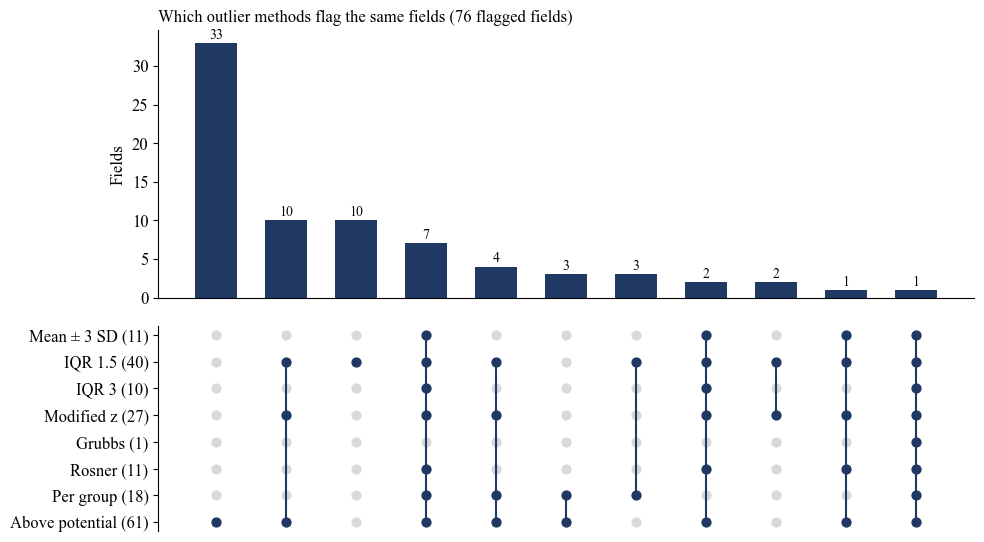

In [7]:
METHODS = list(M.columns)
f[METHODS] = M.reindex(f.index).fillna(False).astype(bool)
f["n_methods"] = f[METHODS].sum(axis=1)
ROBUST = ["iqr_1.5", "iqr_3", "mod_z_3.5", "per_group_mod_z"]
print("fields flagged by how many methods:", f.loc[ok, "n_methods"].value_counts().sort_index().to_dict())

# UpSet-style figure: bars = fields per combination, dots below = which methods are in it
SHORT = {"mean_3sd": "Mean ± 3 SD", "iqr_1.5": "IQR 1.5", "iqr_3": "IQR 3", "mod_z_3.5": "Modified z",
         "grubbs": "Grubbs", "rosner_k20": "Rosner", "per_group_mod_z": "Per group", "above_potential": "Above potential"}
fl = f.loc[ok & (f["n_methods"] > 0), METHODS]
combos = fl.apply(lambda r: tuple(c for c in METHODS if r[c]), axis=1).value_counts()
fig, (a1, a2) = plt.subplots(2, 1, figsize=(10, 5.6), gridspec_kw={"height_ratios": [1.3, 1]}, sharex=True)
x = np.arange(len(combos))
a1.bar(x, combos.values, color="#1F3864", width=0.6)
for i, val in enumerate(combos.values): a1.text(i, val + 0.6, str(val), ha="center", fontsize=10)
a1.set_ylabel("Fields"); a1.set_title(f"Which outlier methods flag the same fields ({len(fl)} flagged fields)", loc="left", fontsize=12)
for j, m in enumerate(METHODS):
    a2.scatter(x, [j] * len(x), s=40, color="#D9D9D9", zorder=1)
for i, combo in enumerate(combos.index):
    ys = [METHODS.index(m) for m in combo]
    a2.scatter([i] * len(ys), ys, s=40, color="#1F3864", zorder=2)
    if len(ys) > 1: a2.plot([i, i], [min(ys), max(ys)], color="#1F3864", lw=1.5, zorder=2)
a2.set_yticks(range(len(METHODS)), [f"{SHORT[m]} ({int(fl[m].sum())})" for m in METHODS])
a2.invert_yaxis(); a2.set_xticks([]); a2.spines["bottom"].set_visible(False)
fig.tight_layout(); fig.savefig(FIG / "B7_method_overlap.png", dpi=300, facecolor="white"); plt.show()

flags = f[["uid", "year", "village", "variety", "crop_yield", "flag_yield_impossible", *METHODS, "n_methods"]]
flags.to_csv(OUT / "B7_outlier_flags.csv", index=False)

**Found:**
- **1,126** fields (94%) are not flagged by any method.
- 43 fields are flagged by 1 method and 8 by 2. 25 fields are flagged by 3 to 8 methods.
- All 43 single-method flags are "above potential" alone (33) or IQR 1.5 alone (10). These are mild.
- The biggest group flagged by many methods (7 fields) is caught by every method except Grubbs. These are the very high yields.
- Grubbs finds only 1 field, the 47 q/acre yield, which every method flags.

## Step 8: Groups and map

Each field gets one `yield_group`:
- **impossible:** yield 0 or above the world record (Step 2)
- **strong:** 3 or more methods, and at least one of them robust (IQR, modified z or per group)
- **weak:** 1 or 2 methods (or 3+ without a robust one)
- **clean:** no method

The non-clean fields are saved as points for QGIS in `B8_yield_outliers_map.gpkg`.

In [8]:
f["yield_group"] = "clean"
f.loc[ok & (f["n_methods"].between(1, 2)), "yield_group"] = "weak"
f.loc[ok & (f["n_methods"] >= 3) & f[ROBUST].any(axis=1), "yield_group"] = "strong"
f.loc[ok & (f["n_methods"] >= 3) & ~f[ROBUST].any(axis=1), "yield_group"] = "weak"
f.loc[f["flag_yield_impossible"], "yield_group"] = "impossible"
grp = pd.crosstab(f["yield_group"], f["year"], margins=True, margins_name="total")
grp.to_csv(OUT / "B8_yield_groups.csv")
print(grp.to_string())
print("\nstrong outliers, yield values:", sorted(f.loc[f["yield_group"] == "strong", "crop_yield"].tolist()))

# map layer for QGIS (points, EPSG:32643)
pts = f[f["yield_group"] != "clean"].copy(); pts["geometry"] = pts.geometry.representative_point()
pts[["year", "village", "crop_yield", "n_methods", "yield_group", "geometry"]].to_file(OUT / "B8_yield_outliers_map.gpkg", layer="yield_outliers", driver="GPKG")
print("map layer saved:", len(pts), "points")

year         2022  2023  2024  2025  total
yield_group                               
clean          50    55   290   731   1126
impossible      0     2     0     1      3
strong          1     1    14     9     25
weak            4     2    19    26     51
total          55    60   323   767   1205

strong outliers, yield values: [15.0, 15.0, 15.0, 15.0, 15.0, 15.75, 16.0, 16.0, 16.0, 17.0, 17.0, 17.0, 17.0, 17.6, 19.0, 20.0, 20.0, 20.3, 22.0, 24.0, 28.0, 32.0, 32.0, 38.0, 47.0]
map layer saved: 79 points


**Found:**
- clean **1,126**, weak **51**, strong **25**, impossible **3** (total 1,205).
- The 25 strong outliers are all high yields, from **15 to 47 q/acre**. 14 of them are from 2024, the year with the highest yields.
- 21 of the 25 are on Flow/Protective irrigation, 13 are in Ausa taluka and 14 are KDS 753. High yields on irrigated land may be **real**, so we do not delete them.
- The 51 weak fields include 15 low yields (1 to 2.4 q/acre). These may be crop failures, which are also real.

### Step 8b: Are the flagged fields packed into a few villages?

If the strong or weak fields sat in only a few villages, that would point to a local cause (for example, one survey team). We draw the same number of fields per year at random 999 times and count how many villages they fall in. This is the same test as R4 Step 10.

Local groups smaller than a village area (hotspots) are tested properly with LISA in Phase 2.

In [9]:
# are the flagged fields packed into fewer villages than chance? (same test as R4 Step 10)
# the same number of fields per year is drawn at random 999 times, and we count the villages they fall in
rng = np.random.default_rng(42)
e = f[ok]
rows = []
for grp_name in ["strong", "weak"]:
    g = f[f["yield_group"] == grp_name]; per_year = g["year"].value_counts()
    sims = np.array([e.loc[np.concatenate([rng.choice(e.index[e["year"] == y_], n, replace=False) for y_, n in per_year.items()]), "village"].nunique()
                     for _ in range(999)])
    obs = g["village"].nunique()
    rows.append({"group": grp_name, "fields": len(g), "villages": obs, "villages_if_random": np.median(sims),
                 "p": (1 + (sims <= obs).sum()) / 1000})
where = pd.DataFrame(rows)
where.to_csv(OUT / "B8_where_flagged.csv", index=False)
print(where.to_string(index=False))

 group  fields  villages  villages_if_random     p
strong      25        17                  19 0.248
  weak      51        31                  31 0.595


**Found:**
- Strong fields are in 17 villages; random draws give 19 (p = 0.248).
- Weak fields are in 31 villages; random draws give 31 (p = 0.595).
- So neither group is packed into a few villages. On the map, a few strong fields sit close together near Killari (south Ausa, 2024). Whether such local groups are more than chance is tested with LISA in Phase 2.

## Step 9: Do the R4 doubt flags go with different yields?

If a doubt flag (from R4) goes with lower or higher yields, the flag may point to a real data problem. For each flag we compare flagged and other fields **inside each year** (Mann-Whitney U), then join the years with Fisher's method and correct for 9 tests with Holm. A year is tested only if it has at least 5 flagged and 5 other fields.

In [10]:
def holm(p):
    p = np.asarray(p, float); order = np.argsort(p); m = len(p)
    adj = np.maximum.accumulate((m - np.arange(m)) * p[order]).clip(max=1); out = np.empty(m); out[order] = adj
    return out

GROUPS = ["flag_harvest_before_maturity", "flag_sowing_missing", "flag_sowing_unusual", "flag_overlap_same_year",
          "flag_harvest_undecided", "flag_variety_unknown", "flag_area_mismatch", "flag_taluka_mismatch", "flag_repeated_plot"]
e = f[ok]
rows = []
for c in GROUPS:
    m = e[c].astype(bool)
    ps = [stats.mannwhitneyu(e.loc[m & (e["year"] == y_), "crop_yield"], e.loc[~m & (e["year"] == y_), "crop_yield"]).pvalue
          for y_ in yrs if (m & (e["year"] == y_)).sum() >= 5 and (~m & (e["year"] == y_)).sum() >= 5]
    rows.append({"flag": c.replace("flag_", ""), "fields": int(m.sum()),
                 "median_flagged": e.loc[m, "crop_yield"].median(), "median_rest": e.loc[~m, "crop_yield"].median(),
                 "years_tested": len(ps), "p_within_years": stats.combine_pvalues(ps, method="fisher").pvalue if ps else np.nan})
dq = pd.DataFrame(rows)
okp = dq["p_within_years"].notna(); dq.loc[okp, "p_holm"] = holm(dq.loc[okp, "p_within_years"])
dq["yield_differs"] = dq["p_holm"] < 0.05
dq.to_csv(OUT / "B9_doubt_flags_vs_yield.csv", index=False)
print(dq.round(3).to_string(index=False))

                   flag  fields  median_flagged  median_rest  years_tested  p_within_years  p_holm  yield_differs
harvest_before_maturity      90             7.6          8.3             3               0       0           True
         sowing_missing      34               9         8.09             2           0.324       1          False
         sowing_unusual      42            7.75          8.3             1           0.011   0.089          False
      overlap_same_year      34               8         8.23             1           0.684       1          False
      harvest_undecided      22               8          8.2             2           0.335       1          False
        variety_unknown      45               9            8             3           0.201       1          False
          area_mismatch      71               9            8             2           0.449       1          False
        taluka_mismatch      46            8.53          8.2             2           0.8

**Found:**
- Only **harvest before maturity** goes with a different yield: median 7.6 vs 8.3, p (Holm) < 0.001. Fields harvested too early give less yield, which makes sense. This supports the R4 finding that these early harvest dates are real.
- Sowing unusual is close (p = 0.011 before correction) but not significant after Holm (0.089).
- All other flags (missing sowing, overlaps, repeated plots, unknown variety, area or taluka mismatch) show **no** link with yield. So keeping these fields does not bias the labels.

## Step 10: Save

In [11]:
f.to_file(DATA2 / "yield_labels_v2.gpkg", driver="GPKG")
print("saved:", DATA2 / "yield_labels_v2.gpkg", "|", len(f), "fields,", f.shape[1], "columns")
print("yield groups:", f["yield_group"].value_counts().to_dict())

saved: f:\THESIS\mtech_thesis_crop_yield_estimation\data\processed_v2\yield_labels_v2.gpkg | 1205 fields, 87 columns
yield groups: {'clean': 1126, 'weak': 51, 'strong': 25, 'impossible': 3}


## Summary

| Question | Answer |
|---|---|
| Unit | q/acre (2 of 3 years, area in acres, potential yield). 2022 does not fit. |
| Impossible yields | 3 (0, 260, 720) |
| Centre and spread | median 8.2 q/acre, IQR 7 to 10, range 1 to 47 |
| Year effect | yes, 2024 is higher (p < 0.001) |
| Shape | not normal, long high tail (skew 3.53) |
| Rounding | 70.5% whole, 16.8% half; accuracy about ±0.5 q/acre |
| Outlier methods | 1 to 61 fields flagged, almost all high |
| Groups | clean 1,126 / weak 51 / strong 25 / impossible 3 |
| Where | not packed into a few villages (strong p = 0.248, weak p = 0.595); local groups tested with LISA in Phase 2 |
| Doubt flags vs yield | only early harvest goes with lower yield |

**Limits**
- The unit is a decision, not a fact. 2022 fits q/ha better.
- The potential yield (3,020 kg/ha) is a 21-site average, not a field maximum, so "above potential" is a soft flag only.
- Bell-curve methods (mean ± 3 SD, Grubbs, Rosner) are weak here because the yield is not normal.
- Spatial outliers and hotspots (LISA, Phase 2) and multivariate outliers (with SAR, Phase 4) are not done yet.

**Next:** Phase 6 tests the handling options: keep all, drop impossible only, drop impossible + strong, or down-weight strong.

**Sources**
- VNMKV RAEEC Latur, RRC 2025 report (official yields): https://www.vnmkv.ac.in/Content/Home/pdf/RAEEC/RRC_2025_Ext_Agronomist_RAEEC_Latur.pdf
- Bhatia et al. 2008, Agricultural and Forest Meteorology (potential yield): https://agris.fao.org/search/ar/records/65de524490674e46e65313b5
- DTN 2023, world record soybean yield: https://www.dtnpf.com/agriculture/web/ag/crops/article/2023/08/24/alex-harrells-soybean-plot-yields